# Task 5 — Association Rule Mining

**Proyek:** *Conference Popularity and Association Pattern Mining Using DBLP Dataset*

Bagian ini menganalisis pola asosiasi antar-konferensi berdasarkan riwayat publikasi penulis pada dataset DBLP periode 2015–2025. Satu transaksi pada representasi **Author-Based** memuat daftar konferensi atau workshop tempat seorang penulis pernah memublikasikan karya. Oleh karena itu, aturan asosiasi yang dihasilkan menggambarkan kecenderungan kemunculan bersama sejumlah venue dalam riwayat publikasi penulis, bukan hubungan sebab-akibat maupun urutan waktu publikasi.

Analisis menggunakan frequent itemsets hasil Task 4 untuk empat ambang minimum support (**0,1%, 0,5%, 1%, dan 2%**) dan minimum confidence **50%**. Pemrosesan dilakukan secara terpisah untuk setiap nilai minimum support agar hasil setiap eksperimen dapat dibandingkan secara konsisten.

Notebook disusun mengikuti keenam butir Task 5 pada dokumen tugas: pembangkitan aturan, penyajian metrik, identifikasi asosiasi menarik dan 10 lift tertinggi, perbandingan support–lift, interpretasi metrik, serta pembahasan pola publikasi. Analisis eksploratif tambahan ditempatkan di bagian lampiran.

## Persiapan Data dan Parameter

Frequent itemsets tidak dihitung ulang pada tahap ini karena telah dihasilkan melalui Task 4. Data masukan terdiri atas empat berkas CSV hasil frequent pattern mining dan berkas ringkasan transaksi Author-Based dari Task 3. Jumlah transaksi digunakan sebagai penyebut dalam perhitungan support dan lift melalui fungsi `generate_rules` yang telah tersedia pada modul proyek.

**Ketentuan reproduksi:** Notebook dijalankan dari folder proyek DBLP atau subfoldernya. Folder proyek perlu memiliki `src/association_rules.py`, `data/results/task3_summary.csv`, dan empat berkas `task4_itemsets_minsup_<nilai>.csv`. Lokasi proyek juga dapat ditetapkan melalui variabel lingkungan `DBLP_PROJECT_ROOT`.

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Menentukan lokasi proyek tanpa memakai path absolut milik komputer tertentu.
project_override = os.environ.get("DBLP_PROJECT_ROOT")
search_roots = ([Path(project_override).expanduser().resolve()] if project_override else [])
cwd = Path.cwd().resolve()
search_roots += [cwd, *cwd.parents]
PROJECT_ROOT = next(
    (path for path in search_roots
     if (path / "src" / "association_rules.py").is_file()
     and (path / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Folder proyek DBLP belum ditemukan. Jalankan notebook dari folder proyek "
        "atau atur variabel lingkungan DBLP_PROJECT_ROOT."
    )
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.association_rules import generate_rules

RESULTS_DIR = PROJECT_ROOT / "data" / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
MIN_CONFIDENCE = 0.50
ITEMSET_FILES = {
    threshold: RESULTS_DIR / f"task4_itemsets_minsup_{threshold}.csv"
    for threshold in MIN_SUPPORTS
}
TASK3_SUMMARY_PATH = RESULTS_DIR / "task3_summary.csv"


def show_table(table, rows=10):
    """Menampilkan tabel dalam bentuk rapi tanpa mengubah data perhitungan."""
    if table.empty:
        print("Tidak ada data yang memenuhi kriteria.")
    else:
        display(table.head(rows).reset_index(drop=True))


def show_rules(table, rows=10):
    """Memformat metrik agar mudah dibaca dalam laporan."""
    if table.empty:
        print("Tidak ditemukan association rule yang memenuhi ambang.")
        return
    columns = [c for c in ["antecedents", "consequents", "support", "confidence", "lift"]
               if c in table.columns]
    view = table[columns].head(rows).copy()
    for metric in ("support", "confidence"):
        if metric in view:
            view[metric] = view[metric].map(lambda x: f"{x:.3%}")
    if "lift" in view:
        view["lift"] = view["lift"].map(lambda x: f"{x:.2f}")
    display(view.reset_index(drop=True))


print(f"Folder proyek   : {PROJECT_ROOT}")
print(f"Minimum support: {', '.join(f'{x:.1%}' for x in MIN_SUPPORTS)}")
print(f"Minimum confidence: {MIN_CONFIDENCE:.0%}")

Folder proyek   : D:\IF4041-project-data-mining
Minimum support: 0.1%, 0.5%, 1.0%, 2.0%
Minimum confidence: 50%


In [2]:
missing_files = [str(path) for path in [*ITEMSET_FILES.values(), TASK3_SUMMARY_PATH]
                 if not path.is_file()]
if missing_files:
    raise FileNotFoundError("File input tidak ditemukan:\n" + "\n".join(missing_files))

task3_summary = pd.read_csv(TASK3_SUMMARY_PATH)
required_summary = {"representasi", "jumlah_transaksi"}
if not required_summary.issubset(task3_summary.columns):
    raise ValueError(f"Kolom ringkasan Task 3 belum lengkap: {required_summary - set(task3_summary.columns)}")
author_rows = task3_summary.loc[
    task3_summary["representasi"].astype(str).str.strip().eq("Author-Based"),
    "jumlah_transaksi",
]
if len(author_rows) != 1:
    raise ValueError("task3_summary.csv harus memiliki tepat satu baris Author-Based.")
total_transactions = int(author_rows.iloc[0])
if total_transactions <= 0:
    raise ValueError("Jumlah transaksi Author-Based harus lebih besar dari 0.")
print(f"Jumlah transaksi Author-Based dari Task 3: {total_transactions:,}")

def load_frequent_itemsets(path):
    table = pd.read_csv(path)
    required_columns = {"itemset", "k", "support_count"}
    missing_columns = required_columns - set(table.columns)
    if missing_columns:
        raise ValueError(f"Kolom CSV {path.name} tidak lengkap: {sorted(missing_columns)}")

    frequent_itemsets = {}
    for row in table.itertuples(index=False):
        items = frozenset(code.strip() for code in str(row.itemset).split(",") if code.strip())
        if not items or len(items) != int(row.k):
            raise ValueError(f"Itemset tidak valid pada {path.name}: {row.itemset!r}")
        count = int(row.support_count)
        if count <= 0 or items in frequent_itemsets:
            raise ValueError(f"Support count/itemset duplikat tidak valid pada {path.name}: {row.itemset!r}")
        frequent_itemsets[items] = count
    return frequent_itemsets

frequent_itemsets_by_support = {
    min_support: load_frequent_itemsets(path)
    for min_support, path in ITEMSET_FILES.items()
}
for min_support, itemsets in frequent_itemsets_by_support.items():
    print(f"min_support={min_support:.1%}: {len(itemsets):,} itemsets "
          f"({sum(len(itemset) == 1 for itemset in itemsets)} singleton, "
          f"{sum(len(itemset) >= 2 for itemset in itemsets)} ukuran >= 2)")

Jumlah transaksi Author-Based dari Task 3: 1,821,757
min_support=0.1%: 1,514 itemsets (574 singleton, 940 ukuran >= 2)
min_support=0.5%: 88 itemsets (66 singleton, 22 ukuran >= 2)
min_support=1.0%: 30 itemsets (29 singleton, 1 ukuran >= 2)
min_support=2.0%: 6 itemsets (6 singleton, 0 ukuran >= 2)


## 1. Pembangkitan Association Rules dari Frequent Itemsets

Setiap frequent itemset yang memiliki sedikitnya dua venue dapat dibagi menjadi **antecedent (A)** dan **consequent (B)** yang tidak saling tumpang tindih. Aturan dituliskan sebagai **A → B**. Pembangkitan dilakukan dengan fungsi `generate_rules` dari implementasi proyek dan hanya mempertahankan aturan dengan confidence minimal 50%.

Masing-masing ambang minimum support diproses secara terpisah. Hasil kemudian diurutkan berdasarkan lift tertinggi, diikuti confidence dan support sebagai pemecah nilai yang sama. Seluruh aturan serta ringkasan jumlahnya disimpan sebagai CSV agar analisis dapat ditelusuri dan digunakan kembali dalam laporan.

In [3]:
REQUIRED_RULE_COLUMNS = {"antecedents", "consequents", "support", "confidence", "lift"}


def format_venues(itemset):
    return ", ".join(sorted(itemset))


rules_by_support = {}
summary_rows = []
all_rules_rows = []
top10_rows = []

for min_support, itemsets in frequent_itemsets_by_support.items():
    rules = generate_rules(
        itemsets,
        total_transactions=total_transactions,
        min_confidence=MIN_CONFIDENCE,
    )
    missing = REQUIRED_RULE_COLUMNS - set(rules.columns)
    if missing:
        raise ValueError(f"Keluaran generate_rules tidak memiliki kolom: {sorted(missing)}")

    # Mengurutkan eksplisit, sehingga pemeringkatan tidak bergantung pada modul asal.
    rules = rules.sort_values(
        ["lift", "confidence", "support"], ascending=[False, False, False], kind="stable"
    ).reset_index(drop=True)
    rules_by_support[min_support] = rules

    if not rules.empty:
        formatted = rules[list(REQUIRED_RULE_COLUMNS)].copy()
        formatted["antecedents"] = formatted["antecedents"].map(format_venues)
        formatted["consequents"] = formatted["consequents"].map(format_venues)
        formatted.insert(0, "min_support", min_support)
        all_rules_rows.extend(formatted.to_dict("records"))

        best = formatted.head(10).copy()
        best.insert(0, "rank_by_lift", range(1, len(best) + 1))
        top10_rows.extend(best.to_dict("records"))

    summary_rows.append({
        "min_support": min_support,
        "frequent_itemsets": len(itemsets),
        "association_rules": len(rules),
        "top_rule_lift": float(rules.iloc[0]["lift"]) if len(rules) else None,
    })

all_rules_display = pd.DataFrame(all_rules_rows, columns=[
    "min_support", "antecedents", "consequents", "support", "confidence", "lift"
])
top10_by_support = pd.DataFrame(top10_rows, columns=[
    "rank_by_lift", "min_support", "antecedents", "consequents",
    "support", "confidence", "lift"
])
summary_df = pd.DataFrame(summary_rows)

all_rules_path = RESULTS_DIR / "task5_association_rules.csv"
top10_path = RESULTS_DIR / "task5_top10_rules_by_lift.csv"
summary_path = RESULTS_DIR / "task5_summary.csv"
all_rules_display.to_csv(all_rules_path, index=False)
top10_by_support.to_csv(top10_path, index=False)
summary_df.to_csv(summary_path, index=False)

print("Ringkasan pembangkitan aturan per nilai minimum support:")
show_table(summary_df, rows=len(summary_df))
print("Berkas hasil:")
for p in (all_rules_path, top10_path, summary_path):
    print(f"- {p.relative_to(PROJECT_ROOT)}")

Ringkasan pembangkitan aturan per nilai minimum support:


,min_support,frequent_itemsets,association_rules,top_rule_lift
0,0.001,1514,1387,172.266902
1,0.005,88,7,33.315261
2,0.010,30,1,18.283887
3,0.020,6,0,NaN


Berkas hasil:
- data\results\task5_association_rules.csv
- data\results\task5_top10_rules_by_lift.csv
- data\results\task5_summary.csv


## 2. Hasil Association Rules: Support, Confidence, dan Lift

Tabel berikut menampilkan contoh aturan dari setiap eksperimen, beserta tiga metrik yang diminta. Nilai **support** dan **confidence** ditampilkan sebagai persentase, sedangkan **lift** ditampilkan dalam bentuk rasio. Tabel pada notebook dibatasi hingga 10 baris per ambang untuk menjaga keterbacaan; seluruh hasil tersedia pada berkas `task5_association_rules.csv`.

Jumlah aturan yang berkurang ketika minimum support dinaikkan menunjukkan bahwa semakin sedikit kombinasi venue yang memenuhi persyaratan frekuensi kemunculan. Perbandingan jumlah tersebut dibahas lebih lanjut pada bagian pola publikasi.

In [4]:
for min_support in MIN_SUPPORTS:
    subset = all_rules_display.loc[all_rules_display["min_support"].eq(min_support)]
    print(f"\nMinimum support {min_support:.1%} — {len(subset):,} association rules")
    show_rules(subset, rows=10)


Minimum support 0.1% — 1,387 association rules


,antecedents,consequents,support,confidence,lift
0,"eccv, mm, nips","aaai, cvpr, iccv",0.100%,61.247%,172.27
1,"cvpr, eccv, icml","iccv, iclr, nips",0.101%,50.231%,171.81
2,"cvpr, iccv, icml, nips","eccv, iclr",0.101%,51.390%,159.38
3,"cvpr, eccv, icml, nips","iccv, iclr",0.101%,59.111%,157.30
4,"eccv, iccv, icml","cvpr, iclr, nips",0.101%,61.367%,156.21
5,"iclr, naacl","acl, emnlp, nips",0.105%,50.381%,152.46
6,"cvpr, iccv, mm, nips","aaai, eccv",0.100%,57.507%,147.66
7,"emnlp, naacl, nips","acl, iclr",0.105%,54.584%,146.26
8,"cvpr, eccv, mm, nips","aaai, iccv",0.100%,68.453%,145.44
9,"cvpr, eccv, icml","iccv, iclr",0.108%,53.600%,142.63



Minimum support 0.5% — 7 association rules


,antecedents,consequents,support,confidence,lift
0,"iclr, nips",icml,0.572%,58.330%,33.32
1,"icml, nips",iclr,0.572%,56.277%,32.91
2,"iclr, icml",nips,0.572%,80.428%,25.35
3,eccv,cvpr,0.755%,58.293%,22.28
4,iccv,cvpr,0.848%,57.026%,21.80
5,icml,nips,1.016%,58.010%,18.28
6,iclr,nips,0.980%,57.312%,18.06



Minimum support 1.0% — 1 association rules


,antecedents,consequents,support,confidence,lift
0,icml,nips,1.016%,58.010%,18.28



Minimum support 2.0% — 0 association rules
Tidak ditemukan association rule yang memenuhi ambang.


## 3. Hubungan Asosiasi yang Menarik dan 10 Rules dengan Lift Tertinggi

Lift menunjukkan kekuatan asosiasi relatif terhadap frekuensi dasar consequent. Aturan dengan lift tertinggi diprioritaskan untuk mengidentifikasi hubungan antar-venue yang paling menonjol secara relatif. Namun, support dan confidence tetap diperhatikan agar aturan yang jarang muncul tidak langsung diperlakukan sebagai pola yang dominan.

Daftar 10 aturan dengan lift tertinggi disajikan untuk **setiap nilai minimum support**. Grafik memperlihatkan hasil pada ambang 0,1%, karena ambang tersebut paling longgar dan memberikan cakupan frequent itemsets yang paling luas dari empat eksperimen. Pada analisis ini, suatu aturan tetap ditafsirkan sebagai asosiasi riwayat publikasi penulis, bukan alur perpindahan penulis antarkonferensi.


10 aturan dengan lift tertinggi — minimum support 0.1%


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift
0,1,0.001,"eccv, mm, nips","aaai, cvpr, iccv",0.100%,61.25%,172.27
1,2,0.001,"cvpr, eccv, icml","iccv, iclr, nips",0.101%,50.23%,171.81
2,3,0.001,"cvpr, iccv, icml, nips","eccv, iclr",0.101%,51.39%,159.38
3,4,0.001,"cvpr, eccv, icml, nips","iccv, iclr",0.101%,59.11%,157.30
4,5,0.001,"eccv, iccv, icml","cvpr, iclr, nips",0.101%,61.37%,156.21
5,6,0.001,"iclr, naacl","acl, emnlp, nips",0.105%,50.38%,152.46
6,7,0.001,"cvpr, iccv, mm, nips","aaai, eccv",0.100%,57.51%,147.66
7,8,0.001,"emnlp, naacl, nips","acl, iclr",0.105%,54.58%,146.26
8,9,0.001,"cvpr, eccv, mm, nips","aaai, iccv",0.100%,68.45%,145.44
9,10,0.001,"cvpr, eccv, icml","iccv, iclr",0.108%,53.60%,142.63



10 aturan dengan lift tertinggi — minimum support 0.5%


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift
0,1,0.005,"iclr, nips",icml,0.572%,58.33%,33.32
1,2,0.005,"icml, nips",iclr,0.572%,56.28%,32.91
2,3,0.005,"iclr, icml",nips,0.572%,80.43%,25.35
3,4,0.005,eccv,cvpr,0.755%,58.29%,22.28
4,5,0.005,iccv,cvpr,0.848%,57.03%,21.80
5,6,0.005,icml,nips,1.016%,58.01%,18.28
6,7,0.005,iclr,nips,0.980%,57.31%,18.06



10 aturan dengan lift tertinggi — minimum support 1.0%


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift
0,1,0.01,icml,nips,1.016%,58.01%,18.28



10 aturan dengan lift tertinggi — minimum support 2.0%
Tidak ada aturan yang memenuhi syarat.

Dua aturan untuk mendukung interpretasi:
Lift tertinggi   : {eccv, mm, nips} → {aaai, cvpr, iccv}; support 0.100%, confidence 61.25%, lift 172.27.
Support tertinggi: {icml} → {nips}; support 1.016%, confidence 58.01%, lift 18.28.


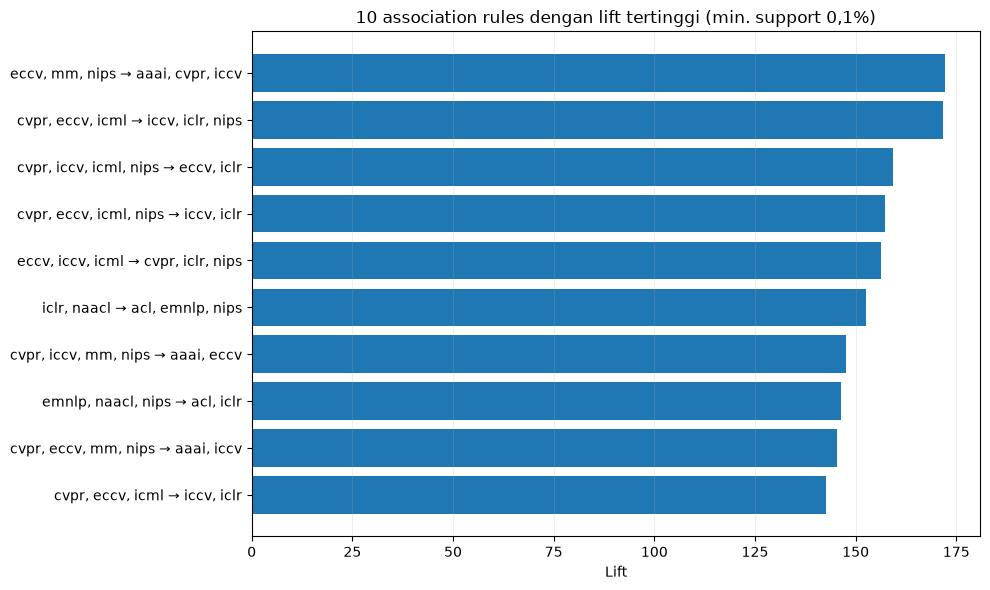

In [5]:
for min_support in MIN_SUPPORTS:
    subset = top10_by_support.loc[top10_by_support["min_support"].eq(min_support)]
    print(f"\n10 aturan dengan lift tertinggi — minimum support {min_support:.1%}")
    if subset.empty:
        print("Tidak ada aturan yang memenuhi syarat.")
    else:
        show_table(subset.assign(
            support=subset["support"].map(lambda x: f"{x:.3%}"),
            confidence=subset["confidence"].map(lambda x: f"{x:.2%}"),
            lift=subset["lift"].map(lambda x: f"{x:.2f}"),
        ), rows=10)

base_rules = all_rules_display.loc[
    all_rules_display["min_support"].eq(MIN_SUPPORTS[0])
].copy()
if not base_rules.empty:
    highest_lift = base_rules.nlargest(1, "lift").iloc[0]
    highest_support = base_rules.nlargest(1, "support").iloc[0]
    print("\nDua aturan untuk mendukung interpretasi:")
    print(f"Lift tertinggi   : {{{highest_lift['antecedents']}}} → {{{highest_lift['consequents']}}}; "
          f"support {highest_lift['support']:.3%}, confidence {highest_lift['confidence']:.2%}, "
          f"lift {highest_lift['lift']:.2f}.")
    print(f"Support tertinggi: {{{highest_support['antecedents']}}} → "
          f"{{{highest_support['consequents']}}}; support {highest_support['support']:.3%}, "
          f"confidence {highest_support['confidence']:.2%}, lift {highest_support['lift']:.2f}.")

best10 = top10_by_support.loc[
    top10_by_support["min_support"].eq(MIN_SUPPORTS[0])
].copy()
if not best10.empty:
    best10["rule"] = best10["antecedents"] + " → " + best10["consequents"]
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(best10["rule"].iloc[::-1], best10["lift"].iloc[::-1])
    ax.set(xlabel="Lift", title="10 association rules dengan lift tertinggi (min. support 0,1%)")
    ax.grid(axis="x", alpha=0.2)
    fig.tight_layout()
    chart_path = FIGURES_DIR / "task5_top10_rules_lift.png"
    fig.savefig(chart_path, dpi=160, bbox_inches="tight")
    plt.show()

## 4. Analisis Hubungan antara Support dan Lift

Analisis ini menguji apakah aturan yang lebih sering ditemukan juga memiliki nilai lift yang lebih tinggi. Perbandingan dilakukan **di dalam setiap eksperimen minimum support**, sehingga aturan dari ambang yang berbeda tidak diperlakukan sebagai pengamatan yang terpisah. Evaluasi menggunakan dua pendekatan: irisan antara 10 aturan dengan support tertinggi dan 10 aturan dengan lift tertinggi, serta korelasi peringkat Spearman antara kedua metrik.

Korelasi digunakan sebagai gambaran kecenderungan, bukan pengujian sebab-akibat. Jika jumlah aturan kurang dari dua atau salah satu metrik tidak bervariasi, koefisien korelasi tidak ditafsirkan.

Perbandingan support dan lift:


,min_support,rule_count,top10_support_lift_overlap,spearman_support_lift
0,0.001,1387,0,-0.209116
1,0.005,7,7,-0.926562
2,0.010,1,1,NaN
3,0.020,0,0,NaN



Aturan dengan support tertinggi berbeda dari aturan dengan lift tertinggi. Dengan demikian, support yang besar tidak selalu disertai lift terbesar.
Min. support 0.5%: seluruh 7 aturan otomatis masuk ke kedua daftar 10 besar; besar irisan tidak mencerminkan kesamaan urutan peringkat.
Min. support 1.0%: seluruh 1 aturan otomatis masuk ke kedua daftar 10 besar; besar irisan tidak mencerminkan kesamaan urutan peringkat.
Min. support 2.0%: tidak ditemukan aturan.


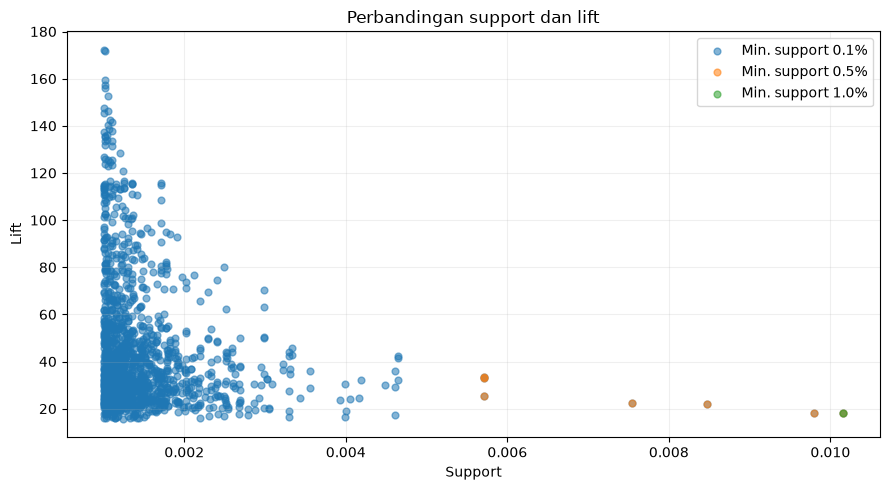

In [6]:
comparison_rows = []
for min_support, rules in rules_by_support.items():
    if rules.empty:
        comparison_rows.append({
            "min_support": min_support, "rule_count": 0,
            "top10_support_lift_overlap": 0, "spearman_support_lift": float("nan"),
        })
        continue

    top_support = rules.nlargest(10, "support")
    top_lift = rules.nlargest(10, "lift")
    support_keys = set(zip(top_support["antecedents"], top_support["consequents"]))
    lift_keys = set(zip(top_lift["antecedents"], top_lift["consequents"]))
    rho = (rules["support"].rank().corr(rules["lift"].rank())
           if len(rules) > 1 and rules["support"].nunique() > 1
           and rules["lift"].nunique() > 1 else float("nan"))
    comparison_rows.append({
        "min_support": min_support,
        "rule_count": len(rules),
        "top10_support_lift_overlap": len(support_keys & lift_keys),
        "spearman_support_lift": rho,
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_path = RESULTS_DIR / "task5_support_lift_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)
print("Perbandingan support dan lift:")
show_table(comparison_df, rows=len(comparison_df))

if not base_rules.empty:
    max_support_rule = base_rules.loc[base_rules["support"].idxmax()]
    max_lift_rule = base_rules.loc[base_rules["lift"].idxmax()]
    if (max_support_rule["antecedents"], max_support_rule["consequents"]) != (
        max_lift_rule["antecedents"], max_lift_rule["consequents"]
    ):
        print("\nAturan dengan support tertinggi berbeda dari aturan dengan lift tertinggi. "
              "Dengan demikian, support yang besar tidak selalu disertai lift terbesar.")
    else:
        print("\nAturan dengan support dan lift tertinggi kebetulan sama pada data ini. "
              "Hubungan keduanya tetap perlu dinilai menggunakan seluruh aturan.")

for row in comparison_df.itertuples(index=False):
    if row.rule_count == 0:
        print(f"Min. support {row.min_support:.1%}: tidak ditemukan aturan.")
    elif row.rule_count <= 10:
        print(f"Min. support {row.min_support:.1%}: seluruh {row.rule_count} aturan "
              "otomatis masuk ke kedua daftar 10 besar; besar irisan tidak mencerminkan "
              "kesamaan urutan peringkat.")

fig, ax = plt.subplots(figsize=(9, 5))
has_points = False
for min_support, rules in rules_by_support.items():
    if not rules.empty:
        ax.scatter(rules["support"], rules["lift"], alpha=0.55, s=24,
                   label=f"Min. support {min_support:.1%}")
        has_points = True
ax.set(title="Perbandingan support dan lift", xlabel="Support", ylabel="Lift")
if has_points:
    ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
figure_path = FIGURES_DIR / "task5_support_vs_lift.png"
fig.savefig(figure_path, dpi=160)
plt.show()

## 5. Interpretasi Support, Confidence, dan Lift

Ketiga metrik memiliki fungsi yang berbeda dalam membaca aturan **A → B**.

- **Support** mengukur proporsi seluruh transaksi yang memuat A dan B sekaligus:  
  \(\operatorname{support}(A\rightarrow B)=\frac{n(A\cap B)}{N}\).
- **Confidence** mengukur proporsi transaksi yang memuat B di antara transaksi yang sudah memuat A:  
  \(\operatorname{confidence}(A\rightarrow B)=\frac{n(A\cap B)}{n(A)}\).
- **Lift** membandingkan confidence dengan proporsi dasar kemunculan B:  
  \(\operatorname{lift}(A\rightarrow B)=\frac{\operatorname{confidence}(A\rightarrow B)}{\operatorname{support}(B)}\).

Nilai **lift > 1** menunjukkan ko-kemunculan positif dibandingkan keadaan independen, **lift = 1** menunjukkan tidak ada penyimpangan dari nilai yang diharapkan pada kondisi independen, dan **lift < 1** menunjukkan asosiasi negatif secara relatif. Support mencerminkan seberapa luas suatu pola ditemukan, confidence mencerminkan peluang bersyarat yang teramati, sedangkan lift membantu menilai apakah peluang tersebut lebih tinggi daripada tingkat kemunculan B secara umum.

Ketika antecedent terdiri atas beberapa venue, confidence merujuk pada penulis yang pernah memublikasikan karya di **seluruh venue antecedent**. Keseluruhan perhitungan ini bersifat deskriptif terhadap transaksi yang digunakan.

In [7]:
# Contoh interpretasi yang diambil langsung dari hasil, bukan angka tetap.
if base_rules.empty:
    print("Contoh numerik belum tersedia karena tidak ada aturan pada ambang 0,1%.")
else:
    example = base_rules.nlargest(1, "lift").iloc[0]
    print(f"Contoh aturan: {{{example['antecedents']}}} → {{{example['consequents']}}}")
    print(f"Support {example['support']:.3%}: sebanyak proporsi tersebut dari seluruh "
          "transaksi penulis memuat kedua sisi aturan secara bersamaan.")
    print(f"Confidence {example['confidence']:.2%}: di antara penulis yang riwayatnya "
          "memuat seluruh venue antecedent, proporsi tersebut juga memiliki "
          "publikasi pada seluruh venue consequent.")
    print(f"Lift {example['lift']:.2f}: ko-kemunculan relatif terhadap peluang dasar "
          "consequent sebesar nilai tersebut, tanpa menunjukkan hubungan kausal.")

Contoh aturan: {eccv, mm, nips} → {aaai, cvpr, iccv}
Support 0.100%: sebanyak proporsi tersebut dari seluruh transaksi penulis memuat kedua sisi aturan secara bersamaan.
Confidence 61.25%: di antara penulis yang riwayatnya memuat seluruh venue antecedent, proporsi tersebut juga memiliki publikasi pada seluruh venue consequent.
Lift 172.27: ko-kemunculan relatif terhadap peluang dasar consequent sebesar nilai tersebut, tanpa menunjukkan hubungan kausal.


## 6. Pola Publikasi Antar-Konferensi

Pola publikasi dinilai dari aturan yang berhasil melewati ambang confidence 50% serta perubahan jumlah aturan pada empat nilai minimum support. Ambang yang lebih rendah memungkinkan kombinasi venue dengan frekuensi relatif kecil tetap ditemukan, sedangkan ambang yang lebih tinggi menyisakan pola yang lebih sering muncul di antara penulis.

Pembahasan utama menekankan dua aspek: **(1)** kombinasi venue yang memiliki asosiasi relatif tinggi berdasarkan lift dan **(2)** kombinasi dengan cakupan transaksi lebih besar berdasarkan support. Keduanya tidak selalu merujuk pada aturan yang sama. Jumlah aturan pada setiap ambang dan beberapa contoh pola yang tetap muncul ditampilkan berikut ini.

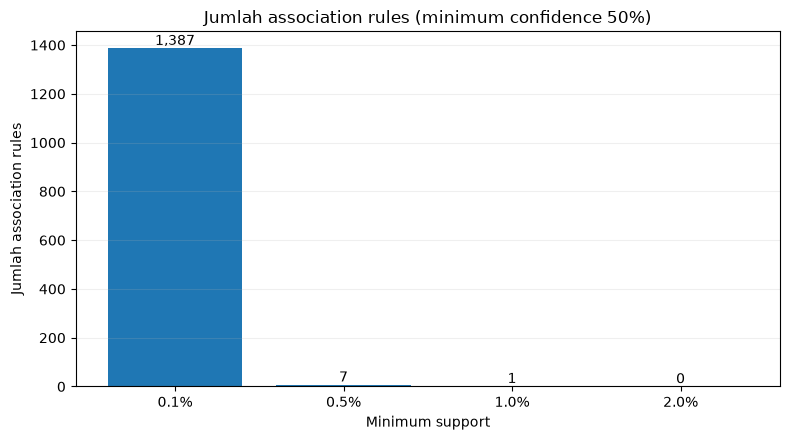

Contoh aturan ber-lift tinggi yang bertahan pada setiap ambang:

Minimum support 0.1%: 1387 aturan


,antecedents,consequents,support,confidence,lift
0,"eccv, mm, nips","aaai, cvpr, iccv",0.100%,61.247%,172.27
1,"cvpr, eccv, icml","iccv, iclr, nips",0.101%,50.231%,171.81
2,"cvpr, iccv, icml, nips","eccv, iclr",0.101%,51.390%,159.38
3,"cvpr, eccv, icml, nips","iccv, iclr",0.101%,59.111%,157.30
4,"eccv, iccv, icml","cvpr, iclr, nips",0.101%,61.367%,156.21



Minimum support 0.5%: 7 aturan


,antecedents,consequents,support,confidence,lift
0,"iclr, nips",icml,0.572%,58.330%,33.32
1,"icml, nips",iclr,0.572%,56.277%,32.91
2,"iclr, icml",nips,0.572%,80.428%,25.35
3,eccv,cvpr,0.755%,58.293%,22.28
4,iccv,cvpr,0.848%,57.026%,21.80



Minimum support 1.0%: 1 aturan


,antecedents,consequents,support,confidence,lift
0,icml,nips,1.016%,58.010%,18.28



Minimum support 2.0%: 0 aturan
Tidak ditemukan association rule yang memenuhi ambang.
Aturan min. support 0.5% merupakan subset dari 0.1%: True
Aturan min. support 1.0% merupakan subset dari 0.5%: True
Aturan min. support 2.0% merupakan subset dari 1.0%: True

Interpretasi: aturan menggambarkan venue yang muncul bersama dalam riwayat publikasi penulis sepanjang periode pengamatan. Tidak dapat disimpulkan bahwa penulis menerbitkan pada tahun yang sama atau berpindah dari A ke B.


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = [f"{value:.1%}" for value in summary_df["min_support"]]
ax.bar(labels, summary_df["association_rules"])
ax.set(xlabel="Minimum support", ylabel="Jumlah association rules",
       title="Jumlah association rules (minimum confidence 50%)")
ax.grid(axis="y", alpha=0.2)
for i, count in enumerate(summary_df["association_rules"]):
    ax.text(i, count, f"{int(count):,}", ha="center", va="bottom")
fig.tight_layout()
count_chart = FIGURES_DIR / "task5_rule_count_by_support.png"
fig.savefig(count_chart, dpi=160)
plt.show()

print("Contoh aturan ber-lift tinggi yang bertahan pada setiap ambang:")
for min_support in MIN_SUPPORTS:
    selected = top10_by_support.loc[top10_by_support["min_support"].eq(min_support)]
    print(f"\nMinimum support {min_support:.1%}: "
          f"{int(summary_df.loc[summary_df['min_support'].eq(min_support), 'association_rules'].iloc[0])} aturan")
    show_rules(selected, rows=5)

# Periksa konsistensi penyaringan: menaikkan minimum support hanya boleh menyaring aturan.
def rule_keys_at(threshold):
    sub = rules_by_support[threshold]
    return set(zip(sub["antecedents"], sub["consequents"]))

for lower, higher in zip(MIN_SUPPORTS[:-1], MIN_SUPPORTS[1:]):
    subset_ok = rule_keys_at(higher).issubset(rule_keys_at(lower))
    print(f"Aturan min. support {higher:.1%} merupakan subset dari {lower:.1%}: {subset_ok}")
    if not subset_ok:
        print("PERHATIAN: Periksa konsistensi frequent itemsets dan fungsi pembangkit aturan.")

print("\nInterpretasi: aturan menggambarkan venue yang muncul bersama dalam riwayat "
      "publikasi penulis sepanjang periode pengamatan. Tidak dapat disimpulkan "
      "bahwa penulis menerbitkan pada tahun yang sama atau berpindah dari A ke B.")

## Kesimpulan Task 5

Berdasarkan rancangan eksperimen, analisis ini menghubungkan frequent itemsets Task 4 dengan aturan asosiasi pada transaksi Author-Based. **Support** digunakan untuk melihat cakupan ko-kemunculan venue, **confidence** untuk menilai keterkaitan bersyarat dari antecedent ke consequent, dan **lift** untuk mengukur kekuatan asosiasi secara relatif. Oleh karena itu, interpretasi aturan tidak cukup didasarkan pada lift saja, tetapi juga mempertimbangkan jumlah transaksi yang mendukung aturan tersebut.

Ringkasan numerik di bawah disusun otomatis dari berkas hasil saat notebook dijalankan. Dengan demikian, jumlah aturan dan contoh asosiasi yang dilaporkan akan tetap mengikuti data aktual ketika input eksperimen berubah.

In [9]:
print("RINGKASAN HASIL TASK 5")
for row in summary_df.itertuples(index=False):
    print(f"Minimum support {row.min_support:.1%}: {row.frequent_itemsets:,} frequent itemsets, "
          f"{row.association_rules:,} association rules (min. confidence 50%).")
if not base_rules.empty:
    best = base_rules.nlargest(1, "lift").iloc[0]
    common = base_rules.nlargest(1, "support").iloc[0]
    print(f"Aturan dengan lift tertinggi (0,1%): {{{best['antecedents']}}} → "
          f"{{{best['consequents']}}} dengan lift {best['lift']:.2f}, "
          f"confidence {best['confidence']:.2%}, dan support {best['support']:.3%}.")
    print(f"Aturan dengan support tertinggi (0,1%): {{{common['antecedents']}}} → "
          f"{{{common['consequents']}}} dengan support {common['support']:.3%}, "
          f"confidence {common['confidence']:.2%}, dan lift {common['lift']:.2f}.")
    rho = comparison_df.loc[comparison_df["min_support"].eq(MIN_SUPPORTS[0]),
                            "spearman_support_lift"].iloc[0]
    if pd.notna(rho):
        print(f"Korelasi peringkat antara support dan lift pada ambang 0,1%: {rho:+.3f}.")

RINGKASAN HASIL TASK 5
Minimum support 0.1%: 1,514 frequent itemsets, 1,387 association rules (min. confidence 50%).
Minimum support 0.5%: 88 frequent itemsets, 7 association rules (min. confidence 50%).
Minimum support 1.0%: 30 frequent itemsets, 1 association rules (min. confidence 50%).
Minimum support 2.0%: 6 frequent itemsets, 0 association rules (min. confidence 50%).
Aturan dengan lift tertinggi (0,1%): {eccv, mm, nips} → {aaai, cvpr, iccv} dengan lift 172.27, confidence 61.25%, dan support 0.100%.
Aturan dengan support tertinggi (0,1%): {icml} → {nips} dengan support 1.016%, confidence 58.01%, dan lift 18.28.
Korelasi peringkat antara support dan lift pada ambang 0,1%: -0.209.


### Keterbatasan Analisis

Interpretasi dibatasi pada publikasi dan venue yang tercakup dalam data DBLP setelah preprocessing. Representasi Author-Based menggabungkan riwayat seluruh periode menjadi satu transaksi per penulis; akibatnya, aturan tidak menggambarkan hubungan kronologis, kolaborasi langsung, atau sebab-akibat. Selain itu, hanya aturan dengan confidence setidaknya 50% yang dilaporkan. Aturan dengan lift tinggi tetapi support rendah perlu dibaca secara hati-hati karena cakupannya terbatas. Kesimpulan tentang perbedaan Author-Based dan Author-Year-Based maupun perbandingan kinerja Apriori dan FP-Growth berada di bagian tugas lain.

**Berkas keluaran utama:** `task5_association_rules.csv`, `task5_top10_rules_by_lift.csv`, `task5_summary.csv`, `task5_support_lift_comparison.csv`, serta grafik pada folder `figures/`.

---

# Lampiran — Analisis Eksploratif Tambahan

Bagian berikut bersifat **pendukung**, di luar enam butir wajib Task 5. Seluruh perhitungan diturunkan dari aturan asosiasi dan frequent itemsets yang telah dimuat pada bagian utama, tanpa memproses ulang dataset DBLP. Analisis tambahan memberikan konteks untuk membaca aturan dengan lift tinggi, melihat kemungkinan redundansi, dan merangkum hubungan antar-venue pada tingkat jaringan.

Metrik tambahan yang digunakan mencakup *leverage*, *conviction*, *Kulczynski*, *cosine*, dan *imbalance ratio*. Metrik tersebut tidak menggantikan tiga metrik wajib, tetapi membantu menghindari kesimpulan yang hanya bergantung pada lift. Pemetaan bidang keilmuan dan pembentukan komunitas jaringan diperlakukan sebagai analisis interpretatif, bukan label resmi yang tersedia langsung dari DBLP.

In [10]:
import itertools
from collections import Counter

import numpy as np

try:
    import networkx as nx
except ImportError:  # grafik jaringan dilewati bila networkx belum terpasang
    nx = None

def split_items(text):
    return frozenset(item.strip() for item in str(text).split(",") if item.strip())

# ---- Metrik tambahan: semuanya diturunkan dari support, confidence, lift ----
# support(A) = support(A->B) / confidence ; support(B) = confidence / lift
ext = all_rules_display.copy()
ext["A"] = ext["antecedents"].map(split_items)
ext["C"] = ext["consequents"].map(split_items)
ext["n_ant"] = ext["A"].map(len)
ext["n_con"] = ext["C"].map(len)
ext["itemset"] = [a | c for a, c in zip(ext["A"], ext["C"])]
ext["supp_A"] = ext["support"] / ext["confidence"]
ext["supp_B"] = ext["confidence"] / ext["lift"]
ext["conf_reverse"] = ext["support"] / ext["supp_B"]          # confidence(B -> A)
ext["leverage"] = ext["support"] - ext["supp_A"] * ext["supp_B"]
ext["conviction"] = (1 - ext["supp_B"]) / (1 - ext["confidence"]).replace(0, np.nan)
ext["kulczynski"] = (ext["confidence"] + ext["conf_reverse"]) / 2
ext["cosine"] = ext["support"] / np.sqrt(ext["supp_A"] * ext["supp_B"])
ext["imbalance_ratio"] = (ext["supp_A"] - ext["supp_B"]).abs() / (
    ext["supp_A"] + ext["supp_B"] - ext["support"]
)

base = ext.loc[ext["min_support"].eq(MIN_SUPPORTS[0])].copy()   # rules pada ambang terendah
if base.empty:
    raise ValueError("Analisis eksploratif tambahan memerlukan setidaknya satu aturan pada min. support 0,1%.")
print(f"Rules pada min_support {MIN_SUPPORTS[0]:.1%}: {len(base):,}")

# ---- Apakah rules pada ambang lebih tinggi adalah himpunan bagian dari ambang 0,1%? ----
base_keys = set(zip(base["A"], base["C"]))
for min_support in MIN_SUPPORTS[1:]:
    keys = set(zip(*[ext.loc[ext["min_support"].eq(min_support), col] for col in ("A", "C")]))
    print(f"min_support={min_support:.1%}: {len(keys)} rules, "
          f"semuanya ada pada hasil 0,1%? {keys <= base_keys}")

metric_cols = ["antecedents", "consequents", "support", "confidence", "lift",
               "leverage", "conviction", "kulczynski", "cosine", "imbalance_ratio"]
extended_path = RESULTS_DIR / "task5_rules_extended_metrics.csv"
base[metric_cols].sort_values("lift", ascending=False).to_csv(extended_path, index=False)
print(f"Rules + metrik tambahan: {extended_path}")
print()
print("Ringkasan metrik (rules pada 0,1%):")
print(base[["support", "confidence", "lift", "leverage", "conviction",
            "kulczynski", "cosine", "imbalance_ratio"]].describe().T[
    ["min", "25%", "50%", "75%", "max"]].to_string(float_format=lambda x: f"{x:.4f}"))

Rules pada min_support 0.1%: 1,387
min_support=0.5%: 7 rules, semuanya ada pada hasil 0,1%? True
min_support=1.0%: 1 rules, semuanya ada pada hasil 0,1%? True
min_support=2.0%: 0 rules, semuanya ada pada hasil 0,1%? True
Rules + metrik tambahan: D:\IF4041-project-data-mining\data\results\task5_rules_extended_metrics.csv

Ringkasan metrik (rules pada 0,1%):
                    min     25%     50%     75%      max
support          0.0010  0.0011  0.0013  0.0016   0.0102
confidence       0.5000  0.5682  0.6467  0.7506   0.9603
lift            15.8258 26.6156 35.5640 51.8519 172.2669
leverage         0.0009  0.0011  0.0012  0.0015   0.0096
conviction       1.9448  2.2830  2.7819  3.9263  24.5125
kulczynski       0.2689  0.3393  0.3817  0.4240   0.5111
cosine           0.1272  0.1892  0.2263  0.2771   0.4585
imbalance_ratio  0.2268  0.7467  0.8489  0.9069   0.9638


## A.1 Struktur Aturan, Redundansi, dan Sensitivitas Confidence

Pemeriksaan ini menjelaskan struktur aturan menurut jumlah venue pada antecedent maupun consequent. Aturan redundan ditandai jika terdapat aturan lain dengan consequent yang sama, antecedent yang merupakan himpunan bagian, dan confidence yang tidak lebih rendah. Definisi operasional tersebut digunakan untuk melihat kemungkinan pengulangan informasi, bukan untuk menyatakan bahwa aturan lain tidak bermanfaat.

Pengaruh perubahan confidence juga diperiksa secara deskriptif dengan menaikkan ambang dari 50% hingga 90%. Karena aturan awal telah disaring pada confidence 50%, perbandingan hanya dapat dilakukan untuk ambang yang sama atau lebih tinggi.

Jumlah rules menurut ukuran antecedent dan consequent:
ukuran consequent    1    2   3
ukuran antecedent              
1                   22    0   0
2                  436   91   3
3                  464  136  10
4                  174   33   0
5                   18    0   0

Itemset unik yang melahirkan rules: 537 (rata-rata 2.58 rule per itemset)
Distribusi ukuran itemset sumber: {2: 22, 3: 316, 4: 159, 5: 37, 6: 3}
Rule dengan satu venue di antecedent dan satu di consequent: 22 dari 1,387 (1.6%)

Rule redundan: 9 dari 1,387 (0.6%)

Jumlah rules jika ambang confidence dinaikkan:
 min_confidence  rules  median_lift
           0.50   1387        35.56
           0.60    900        34.86
           0.70    508        31.74
           0.80    223        31.90
           0.90     44        34.72


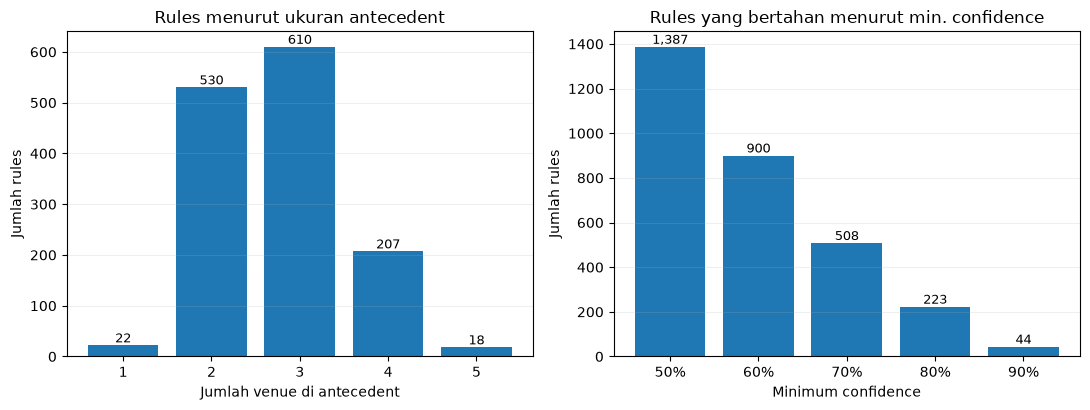

In [11]:
# (1) Ukuran antecedent x consequent
size_table = pd.crosstab(base["n_ant"], base["n_con"])
size_table.index.name, size_table.columns.name = "ukuran antecedent", "ukuran consequent"
print("Jumlah rules menurut ukuran antecedent dan consequent:")
print(size_table.to_string())

unique_itemsets = base["itemset"].drop_duplicates()
print(f"\nItemset unik yang melahirkan rules: {len(unique_itemsets):,} "
      f"(rata-rata {len(base) / len(unique_itemsets):.2f} rule per itemset)")
print("Distribusi ukuran itemset sumber:",
      dict(sorted(Counter(map(len, unique_itemsets)).items())))
print(f"Rule dengan satu venue di antecedent dan satu di consequent: "
      f"{int(((base['n_ant'] == 1) & (base['n_con'] == 1)).sum())} "
      f"dari {len(base):,} ({((base['n_ant'] == 1) & (base['n_con'] == 1)).mean():.1%})")

# (2) Rule redundan
by_consequent = {}
for idx, row in base.iterrows():
    by_consequent.setdefault(row["C"], []).append((idx, row["A"], row["confidence"]))
redundant_idx = set()
for entries in by_consequent.values():
    for idx, ant, conf in entries:
        if any(other_ant < ant and other_conf >= conf for _, other_ant, other_conf in entries):
            redundant_idx.add(idx)
print(f"\nRule redundan: {len(redundant_idx)} dari {len(base):,} ({len(redundant_idx) / len(base):.1%})")

# (3) Kekokohan terhadap ambang confidence (hanya bisa dinaikkan dari 50%)
conf_rows = []
for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    subset = base.loc[base["confidence"] >= threshold]
    conf_rows.append({"min_confidence": threshold, "rules": len(subset),
                      "median_lift": subset["lift"].median() if len(subset) else np.nan})
conf_df = pd.DataFrame(conf_rows)
print("\nJumlah rules jika ambang confidence dinaikkan:")
print(conf_df.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
by_ant = base["n_ant"].value_counts().sort_index()
axes[0].bar(by_ant.index.astype(str), by_ant.values)
axes[0].set(title="Rules menurut ukuran antecedent", xlabel="Jumlah venue di antecedent", ylabel="Jumlah rules")
for i, v in enumerate(by_ant.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axes[1].bar([f"{t:.0%}" for t in conf_df["min_confidence"]], conf_df["rules"])
axes[1].set(title="Rules yang bertahan menurut min. confidence", xlabel="Minimum confidence", ylabel="Jumlah rules")
for i, v in enumerate(conf_df["rules"]):
    axes[1].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task5_extra_rule_structure.png", dpi=160)
plt.show()

## A.2 Pengaruh Frekuensi Consequent terhadap Lift

Secara matematis, \(\operatorname{lift}(A\rightarrow B)=\operatorname{confidence}(A\rightarrow B)/\operatorname{support}(B)\). Pada confidence yang sama, consequent yang jarang ditemukan akan menghasilkan lift lebih besar. Karena itu, hubungan lift dengan support aturan dan support consequent diperiksa secara terpisah, termasuk melalui korelasi peringkat dan pengelompokan berdasarkan kuartil support. Hasilnya digunakan untuk membaca apakah aturan dengan lift tertinggi juga memiliki cakupan yang cukup luas.

support(B) terbesar pada consequent rules : 3.1728%
Batas bawah lift teoretis (0,5 / support(B)maks): 15.76
Lift terkecil yang teramati                     : 15.83
Batas bawah tersebut berlaku untuk aturan yang memenuhi min. confidence. Nilai lift tetap perlu dibaca bersama support dan confidence.

Korelasi peringkat Spearman (rules pada 0,1%):
  lift vs support rule  : -0.209
  lift vs confidence    : -0.074
  lift vs support(B)    : -0.911
  lift vs support(A)    : -0.111

Median lift menurut kuartil support rule:
                  rules  median_support  median_confidence  median_lift  max_lift
support_quartile                                                                 
Q1 (terendah)       347          0.0010             0.6536      43.5004  172.2669
Q2                  347          0.0012             0.6512      35.9943  128.5364
Q3                  346          0.0014             0.6400      33.6016  115.6353
Q4 (tertinggi)      347          0.0019             0.6428      32.1

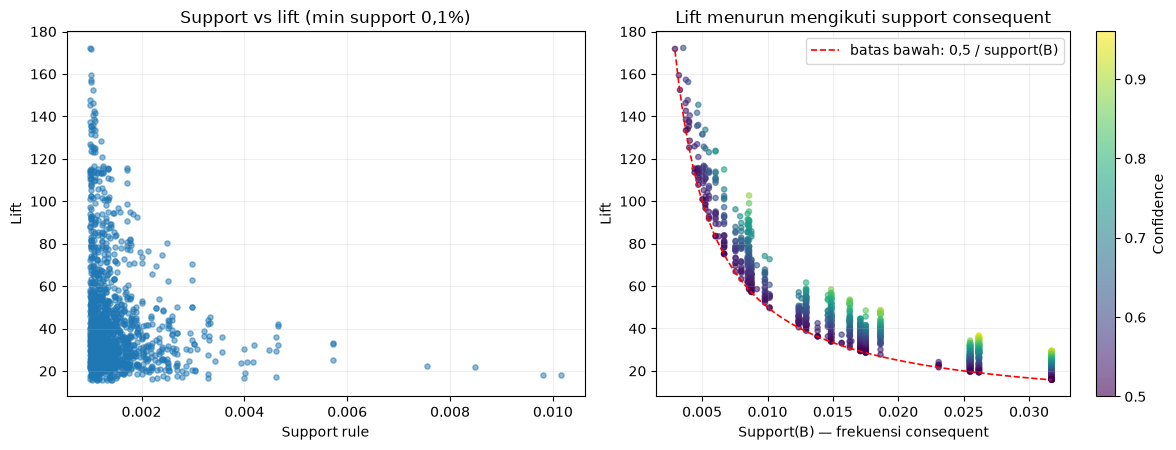

In [12]:
max_supp_b = base["supp_B"].max()
print(f"support(B) terbesar pada consequent rules : {max_supp_b:.4%}")
print(f"Batas bawah lift teoretis (0,5 / support(B)maks): {MIN_CONFIDENCE / max_supp_b:.2f}")
print(f"Lift terkecil yang teramati                     : {base['lift'].min():.2f}")
print("Batas bawah tersebut berlaku untuk aturan yang memenuhi min. confidence. "
      "Nilai lift tetap perlu dibaca bersama support dan confidence.")

def spearman(x, y):
    return x.rank().corr(y.rank())

print("\nKorelasi peringkat Spearman (rules pada 0,1%):")
print(f"  lift vs support rule  : {spearman(base['lift'], base['support']):+.3f}")
print(f"  lift vs confidence    : {spearman(base['lift'], base['confidence']):+.3f}")
print(f"  lift vs support(B)    : {spearman(base['lift'], base['supp_B']):+.3f}")
print(f"  lift vs support(A)    : {spearman(base['lift'], base['supp_A']):+.3f}")

base["support_quartile"] = pd.qcut(base["support"].rank(method="first"), 4, labels=["Q1 (terendah)", "Q2", "Q3", "Q4 (tertinggi)"])
quartile_table = base.groupby("support_quartile", observed=True).agg(
    rules=("lift", "size"), median_support=("support", "median"),
    median_confidence=("confidence", "median"), median_lift=("lift", "median"),
    max_lift=("lift", "max"),
)
print("\nMedian lift menurut kuartil support rule:")
print(quartile_table.to_string(float_format=lambda x: f"{x:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].scatter(base["support"], base["lift"], s=14, alpha=0.5)
axes[0].set(xlabel="Support rule", ylabel="Lift", title="Support vs lift (min support 0,1%)")
sc = axes[1].scatter(base["supp_B"], base["lift"], c=base["confidence"], s=14, alpha=0.6, cmap="viridis")
grid = np.linspace(base["supp_B"].min(), base["supp_B"].max(), 100)
axes[1].plot(grid, MIN_CONFIDENCE / grid, "r--", lw=1.2, label="batas bawah: 0,5 / support(B)")
axes[1].set(xlabel="Support(B) — frekuensi consequent", ylabel="Lift",
            title="Lift menurun mengikuti support consequent")
axes[1].legend()
fig.colorbar(sc, ax=axes[1], label="Confidence")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task5_extra_support_vs_lift.png", dpi=160)
plt.show()

## A.3 Asosiasi Menarik Berdasarkan Kulczynski dan Cosine

Untuk melengkapi pengurutan berdasarkan lift, asosiasi juga dibandingkan menggunakan *Kulczynski* dan *cosine*. Kulczynski merupakan rata-rata confidence dari dua arah aturan, sedangkan cosine mengukur tingkat ko-kemunculan yang dinormalisasi terhadap support kedua sisi. Keseimbangan kedua arah harus dilihat dari confidence A → B dan B → A, bukan hanya nilai Kulczynski. Analisis dibatasi pada hasil minimum support 0,1%.

10 rules teratas menurut KULCZYNSKI:


,antecedents,consequents,support,confidence,lift,kulczynski,cosine
0,"eccv, iccv, nips",cvpr,0.002990,0.907833,34.698131,0.511056,0.322097
1,"eccv, iccv",cvpr,0.004652,0.843100,32.223978,0.510443,0.387158
2,"aaai, eccv, iccv, nips",cvpr,0.001769,0.937445,35.829930,0.502522,0.251733
3,"eccv, iccv, iclr, nips",cvpr,0.001708,0.935377,35.750881,0.500334,0.247126
4,"eccv, iccv, iclr, icml","cvpr, nips",0.001015,0.881736,102.705140,0.499979,0.322864
5,"eccv, iccv, nips, wacv",cvpr,0.001008,0.960272,36.702373,0.499406,0.192378
6,"eccv, iccv, iclr",cvpr,0.002015,0.919589,35.147449,0.498304,0.266130
7,"aaai, eccv, iccv, mm, nips",cvpr,0.001003,0.957046,36.579063,0.497688,0.191532
8,"aaai, eccv, iccv, iclr, nips",cvpr,0.001101,0.952494,36.405101,0.497280,0.200167
9,"aaai, eccv, iccv",cvpr,0.002290,0.906739,34.656310,0.497124,0.281686



10 rules teratas menurut COSINE:


,antecedents,consequents,support,confidence,lift,kulczynski,cosine
0,"eccv, nips","cvpr, iccv",0.002990,0.595887,70.303782,0.474324,0.458483
1,ecoc,ofc,0.002487,0.664710,80.115148,0.482206,0.446335
2,"cvpr, iccv, iclr","eccv, nips",0.001708,0.579840,115.559254,0.460142,0.444301
3,"cvpr, iccv",eccv,0.004652,0.548799,42.379627,0.454002,0.443994
4,"eccv, iclr","cvpr, iccv, nips",0.001708,0.529792,114.803478,0.449980,0.442845
5,"cvpr, eccv",iccv,0.004652,0.616201,41.458396,0.464580,0.439142
6,"iclr, nips",icml,0.005716,0.583296,33.315261,0.454882,0.436379
7,"eccv, iccv","cvpr, nips",0.002990,0.541936,63.125060,0.445105,0.434445
8,"icml, nips",iclr,0.005716,0.562774,32.913954,0.448535,0.433743
9,"cvpr, eccv, iclr","iccv, nips",0.001708,0.655158,108.711038,0.469304,0.430935



Irisan top-10 lift vs top-10 Kulczynski: 0
Irisan top-10 lift vs top-10 cosine    : 0
Irisan top-10 Kulczynski vs top-10 cosine: 0

Korelasi peringkat antar metrik (Spearman):
            support  confidence  lift  leverage  kulczynski  cosine
support       +1.00       -0.05 -0.21     +1.00       +0.07   +0.31
confidence    -0.05       +1.00 -0.07     -0.05       +0.82   -0.14
lift          -0.21       -0.07 +1.00     -0.14       +0.32   +0.81
leverage      +1.00       -0.05 -0.14     +1.00       +0.10   +0.38
kulczynski    +0.07       +0.82 +0.32     +0.10       +1.00   +0.35
cosine        +0.31       -0.14 +0.81     +0.38       +0.35   +1.00

Rule 1 -> 1 (hubungan langsung antar dua venue), diurutkan menurut Kulczynski:


,antecedents,consequents,support,confidence,lift,kulczynski,cosine,imbalance_ratio
0,ecoc,ofc,0.002487,0.664710,80.115148,0.482206,0.446335,0.477011
1,icml,nips,0.010157,0.580104,18.283887,0.450113,0.430933,0.363856
2,iccv,cvpr,0.008476,0.570263,21.795902,0.447109,0.429813,0.347167
3,iclr,nips,0.009799,0.573116,18.063645,0.440987,0.420728,0.374854
4,eccv,cvpr,0.007549,0.582934,22.280220,0.435727,0.410107,0.418639
5,asru,interspeech,0.001076,0.726565,74.173471,0.418228,0.282565,0.815046
6,naacl,emnlp,0.004480,0.560038,30.048122,0.400211,0.366912,0.480107
7,naacl,acl,0.004188,0.523466,32.133594,0.390267,0.366833,0.412402
8,aistats,nips,0.002873,0.611949,19.287585,0.351251,0.235402,0.805756
9,eacl,emnlp,0.001649,0.612311,32.852762,0.350392,0.232751,0.810129


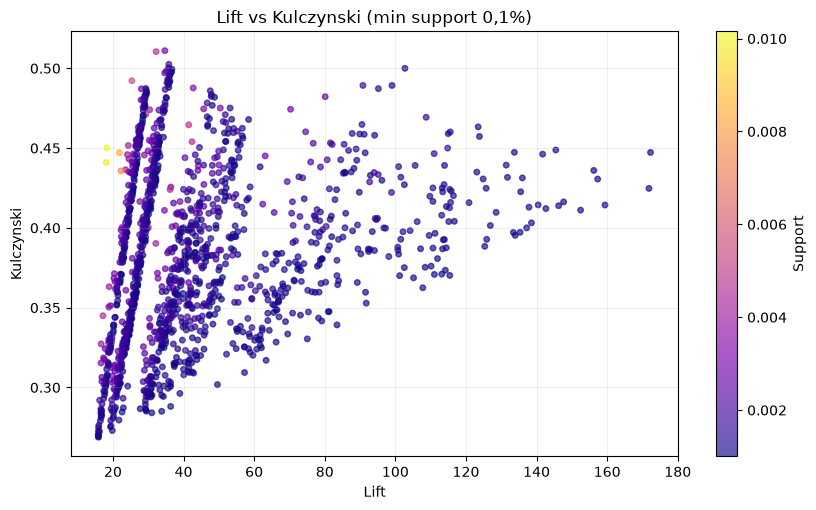

In [13]:
show_cols = ["antecedents", "consequents", "support", "confidence", "lift", "kulczynski", "cosine"]
top_lift = base.nlargest(10, "lift")
top_kulc = base.nlargest(10, "kulczynski")
top_cos = base.nlargest(10, "cosine")

print("10 rules teratas menurut KULCZYNSKI:")
show_table(top_kulc[show_cols], rows=10)
print("\n10 rules teratas menurut COSINE:")
show_table(top_cos[show_cols], rows=10)

keys = lambda df: set(zip(df["A"], df["C"]))
print(f"\nIrisan top-10 lift vs top-10 Kulczynski: {len(keys(top_lift) & keys(top_kulc))}")
print(f"Irisan top-10 lift vs top-10 cosine    : {len(keys(top_lift) & keys(top_cos))}")
print(f"Irisan top-10 Kulczynski vs top-10 cosine: {len(keys(top_kulc) & keys(top_cos))}")

print("\nKorelasi peringkat antar metrik (Spearman):")
metrics = ["support", "confidence", "lift", "leverage", "kulczynski", "cosine"]
rank_corr = base[metrics].rank().corr()
print(rank_corr.to_string(float_format=lambda x: f"{x:+.2f}"))

print("\nRule 1 -> 1 (hubungan langsung antar dua venue), diurutkan menurut Kulczynski:")
direct = base.loc[(base["n_ant"] == 1) & (base["n_con"] == 1)].sort_values("kulczynski", ascending=False)
show_table(direct[show_cols + ["imbalance_ratio"]], rows=len(direct))

fig, ax = plt.subplots(figsize=(8.5, 5.2))
sc = ax.scatter(base["lift"], base["kulczynski"], c=base["support"], s=16, alpha=0.65, cmap="plasma")
ax.set(xlabel="Lift", ylabel="Kulczynski", title="Lift vs Kulczynski (min support 0,1%)")
fig.colorbar(sc, ax=ax, label="Support")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task5_extra_lift_vs_kulczynski.png", dpi=160)
plt.show()

## A.4 Keterlibatan Venue dalam Association Rules

Selain frekuensi suatu venue pada transaksi, analisis ini menghitung seberapa sering venue muncul pada sisi antecedent maupun consequent. Perbandingan dilakukan untuk menilai apakah venue dengan support tunggal yang tinggi juga banyak terlibat dalam aturan asosiasi. Jumlah kemunculan pada aturan tidak sama dengan jumlah penulis atau publikasi, karena satu venue dapat muncul pada beberapa aturan yang berasal dari itemsets yang sama.

Venue yang muncul di rules: 52 dari 574 venue frequent 1-itemset

15 venue dengan keterlibatan terbanyak dalam rules:


,venue,support_venue,as_antecedent,as_consequent,median_lift,max_kulczynski,rules_total,share_of_rules
0,NIPS,0.031728,441,393,34.116148,0.511056,834,0.601298
1,AAAI,0.025490,390,266,32.438760,0.502522,656,0.472963
2,CVPR,0.026164,364,290,35.790254,0.511056,654,0.471521
3,ICCV,0.014863,379,166,43.638024,0.511056,545,0.392934
4,ICLR,0.017098,349,130,37.265031,0.500334,479,0.345350
5,ECCV,0.012950,336,105,47.274857,0.511056,441,0.317952
6,ICML,0.017508,324,81,36.724428,0.499979,405,0.291997
7,EMNLP,0.018638,162,76,38.136147,0.487691,238,0.171593
8,ACL,0.016290,160,71,38.336650,0.487691,231,0.166547
9,MM,0.012384,195,24,37.361325,0.497688,219,0.157895



10 venue dengan support publikasi tertinggi (frequent 1-itemset Task 4) dan keterlibatannya:
  NIPS         support=3.1728%  keterlibatan dalam rules=834
  CVPR         support=2.6164%  keterlibatan dalam rules=654
  AAAI         support=2.5490%  keterlibatan dalam rules=656
  ICASSP       support=2.3086%  keterlibatan dalam rules=97
  EMBC         support=2.1582%  keterlibatan dalam rules=0
  HCI          support=2.0795%  keterlibatan dalam rules=0
  IGARSS       support=1.9338%  keterlibatan dalam rules=0
  EMNLP        support=1.8638%  keterlibatan dalam rules=238
  ICML         support=1.7508%  keterlibatan dalam rules=405
  IROS         support=1.7153%  keterlibatan dalam rules=10

Spearman support venue vs jumlah keterlibatan dalam rules: +0.699  (n=52)
Tabel venue: D:\IF4041-project-data-mining\data\results\task5_venue_involvement.csv


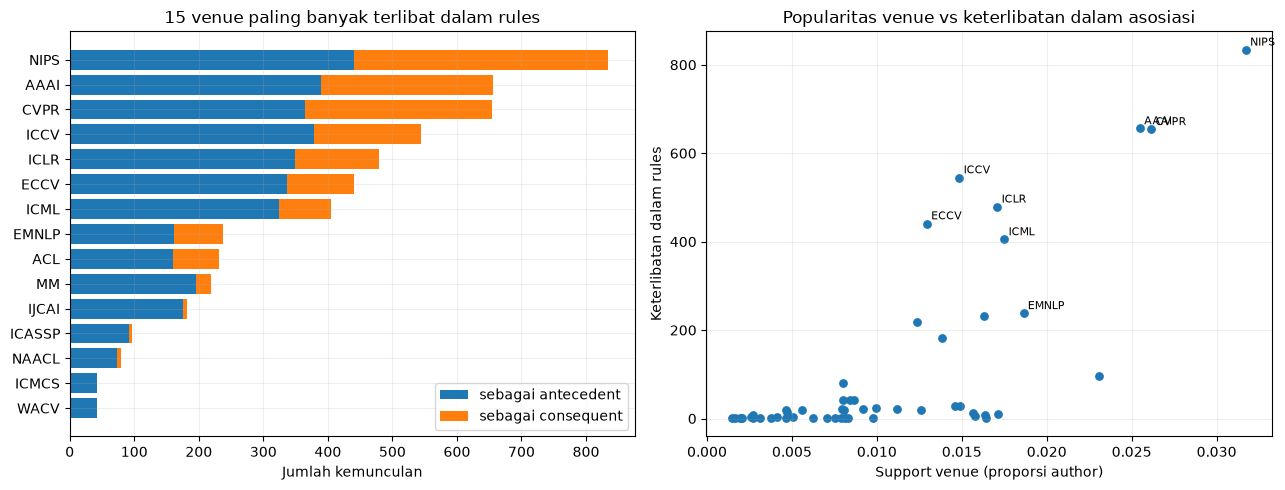

In [14]:
single_support = {
    next(iter(itemset)): count / total_transactions
    for itemset, count in frequent_itemsets_by_support[MIN_SUPPORTS[0]].items()
    if len(itemset) == 1
}

ant_count, con_count = Counter(), Counter()
lift_by_venue, kulc_by_venue = {}, {}
for row in base.itertuples():
    for venue in row.A:
        ant_count[venue] += 1
    for venue in row.C:
        con_count[venue] += 1
    for venue in row.A | row.C:
        lift_by_venue.setdefault(venue, []).append(row.lift)
        kulc_by_venue.setdefault(venue, []).append(row.kulczynski)

venues = sorted(set(ant_count) | set(con_count))
venue_df = pd.DataFrame({
    "venue": [v.upper() for v in venues],
    "support_venue": [single_support.get(v, np.nan) for v in venues],
    "as_antecedent": [ant_count[v] for v in venues],
    "as_consequent": [con_count[v] for v in venues],
    "median_lift": [np.median(lift_by_venue[v]) for v in venues],
    "max_kulczynski": [np.max(kulc_by_venue[v]) for v in venues],
})
venue_df["rules_total"] = venue_df["as_antecedent"] + venue_df["as_consequent"]
venue_df["share_of_rules"] = [
    sum(v in itemset for itemset in base["itemset"]) / len(base) for v in venues
]
venue_df = venue_df.sort_values("rules_total", ascending=False).reset_index(drop=True)

print(f"Venue yang muncul di rules: {len(venue_df)} dari {len(single_support)} venue frequent 1-itemset")
print("\n15 venue dengan keterlibatan terbanyak dalam rules:")
show_table(venue_df, rows=15)

print("\n10 venue dengan support publikasi tertinggi (frequent 1-itemset Task 4) dan keterlibatannya:")
top_support_venues = sorted(single_support.items(), key=lambda kv: -kv[1])[:10]
for venue, supp in top_support_venues:
    row = venue_df.loc[venue_df["venue"].eq(venue.upper())]
    n_rules = int(row["rules_total"].iloc[0]) if not row.empty else 0
    print(f"  {venue.upper():<12} support={supp:.4%}  keterlibatan dalam rules={n_rules}")

valid = venue_df.dropna(subset=["support_venue"])
print(f"\nSpearman support venue vs jumlah keterlibatan dalam rules: "
      f"{spearman(valid['support_venue'], valid['rules_total']):+.3f}  (n={len(valid)})")

venue_path = RESULTS_DIR / "task5_venue_involvement.csv"
venue_df.to_csv(venue_path, index=False)
print(f"Tabel venue: {venue_path}")

top15 = venue_df.head(15).iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(top15["venue"], top15["as_antecedent"], label="sebagai antecedent")
axes[0].barh(top15["venue"], top15["as_consequent"], left=top15["as_antecedent"], label="sebagai consequent")
axes[0].set(title="15 venue paling banyak terlibat dalam rules", xlabel="Jumlah kemunculan")
axes[0].legend()
axes[1].scatter(valid["support_venue"], valid["rules_total"], s=28)
for row in valid.nlargest(8, "rules_total").itertuples():
    axes[1].annotate(row.venue, (row.support_venue, row.rules_total), fontsize=8,
                     xytext=(3, 3), textcoords="offset points")
axes[1].set(xlabel="Support venue (proporsi author)", ylabel="Keterlibatan dalam rules",
            title="Popularitas venue vs keterlibatan dalam asosiasi")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "task5_extra_venue_involvement.png", dpi=160)
plt.show()

## A.5 Jaringan Asosiasi dan Pengelompokan Bidang

Jaringan dibentuk dari pasangan venue yang muncul bersama dalam frequent itemset unik yang menghasilkan aturan. Bobot hubungan merepresentasikan **jumlah itemset yang memuat pasangan venue**, bukan jumlah transaksi atau frekuensi publikasi langsung. Komponen terhubung dihitung terlebih dahulu; apabila `networkx` tersedia, algoritma *greedy modularity* digunakan untuk memperoleh gambaran komunitas pada jaringan.

Kategori bidang seperti machine learning, computer vision, dan NLP berasal dari **pemetaan manual** berdasarkan nama venue. Kategori tersebut digunakan sebagai alat bantu interpretasi dan dapat ditinjau ulang sebelum dilaporkan sebagai temuan bidang keilmuan.

In [15]:
DOMAIN_MAP = {
    # Computer vision / citra
    "cvpr": "CV", "iccv": "CV", "eccv": "CV", "bmvc": "CV", "accv": "CV", "3dim": "CV",
    "wacv": "CV", "iccvw": "CV", "icip": "CV", "icpr": "CV", "miccai": "CV",
    # Machine learning
    "nips": "ML", "neurips": "ML", "icml": "ML", "iclr": "ML", "aistats": "ML", "uai": "ML", "ijcnn": "ML",
    # NLP
    "acl": "NLP", "emnlp": "NLP", "naacl": "NLP", "eacl": "NLP", "coling": "NLP", "ijcnlp": "NLP",
    # AI umum
    "aaai": "AI umum", "ijcai": "AI umum",
    # Data mining / web / IR
    "kdd": "DM/Web/IR", "cikm": "DM/Web/IR", "www": "DM/Web/IR", "sigir": "DM/Web/IR", "icdm": "DM/Web/IR",
    # Robotika
    "icra": "Robotika", "iros": "Robotika", "corl": "Robotika",
    # Multimedia
    "mm": "Multimedia", "icmcs": "Multimedia",
    # Komunikasi nirkabel / jaringan
    "globecom": "Komunikasi", "icc": "Komunikasi", "vtc": "Komunikasi", "wcnc": "Komunikasi",
    "pimrc": "Komunikasi", "spawc": "Komunikasi", "infocom": "Komunikasi",
    # Sinyal / ucapan
    "icassp": "Sinyal/Ucapan", "interspeech": "Sinyal/Ucapan", "asru": "Sinyal/Ucapan",
    # Komunikasi optik
    "ofc": "Optik", "ecoc": "Optik",
    # Kontrol
    "cdc": "Kontrol", "amcc": "Kontrol", "eucc": "Kontrol",
    # HCI
    "chi": "HCI", "acmdis": "HCI",
}
domain_of = lambda venue: DOMAIN_MAP.get(venue, "Lainnya")

# ---- Graf venue dari itemset unik ----
edge_weight = Counter()
for itemset in unique_itemsets:
    for u, v in itertools.combinations(sorted(itemset), 2):
        edge_weight[(u, v)] += 1

# Komponen terhubung (union-find sederhana, tanpa dependensi)
parent = {}
def find(x):
    parent.setdefault(x, x)
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x
for (u, v) in edge_weight:
    parent[find(u)] = find(v)
components = {}
for node in list(parent):
    components.setdefault(find(node), []).append(node)
components = sorted(components.values(), key=len, reverse=True)
print(f"Komponen terhubung: {len(components)}")
for i, comp in enumerate(components, 1):
    print(f"  K{i} ({len(comp)} venue): " + ", ".join(sorted(v.upper() for v in comp)))

# ---- Komunitas ----
communities = [set(c) for c in components]
G = None
if nx is not None:
    G = nx.Graph()
    for (u, v), w in edge_weight.items():
        G.add_edge(u, v, weight=w)
    communities = [set(c) for c in nx.community.greedy_modularity_communities(G, weight="weight")]
    print(f"\nKomunitas (greedy modularity), modularity = "
          f"{nx.community.modularity(G, communities, weight='weight'):.3f}")
else:
    print("\nnetworkx tidak terpasang: komunitas = komponen terhubung (pip install networkx untuk analisis penuh).")
for i, comm in enumerate(communities, 1):
    doms = Counter(domain_of(v) for v in comm).most_common()
    print(f"  C{i} ({len(comm)} venue): " + ", ".join(sorted(v.upper() for v in comm)))
    print("      bidang: " + ", ".join(f"{d} ({n})" for d, n in doms))

# ---- Intra-bidang vs lintas-bidang ----
domain_sets = unique_itemsets.map(lambda s: frozenset(domain_of(v) for v in s))
cross = domain_sets.map(len) > 1
print(f"\nItemset yang seluruh venue-nya satu bidang : {int((~cross).sum())} dari {len(cross)} ({(~cross).mean():.1%})")
print(f"Itemset lintas-bidang                       : {int(cross.sum())} dari {len(cross)} ({cross.mean():.1%})")
pair_counter = Counter()
for dset in domain_sets[cross]:
    for pair in itertools.combinations(sorted(dset), 2):
        pair_counter[pair] += 1
print("\nPasangan bidang yang paling sering muncul bersama dalam itemset lintas-bidang:")
for (d1, d2), n in pair_counter.most_common(8):
    print(f"  {d1} + {d2}: {n} itemset")

# ---- Visualisasi jaringan (tata letak melingkar, node dikelompokkan per komunitas) ----
if G is not None:
    participation = Counter()
    for itemset in unique_itemsets:
        for v in itemset:
            participation[v] += 1
    palette = plt.get_cmap("tab10")
    ordered = [v for comm in communities for v in sorted(comm, key=lambda x: -participation[x])]
    color_of = {v: palette(i % 10) for i, comm in enumerate(communities) for v in comm}
    angles = np.linspace(0, 2 * np.pi, len(ordered), endpoint=False)
    pos = {v: (np.cos(a), np.sin(a)) for v, a in zip(ordered, angles)}
    max_w = max(edge_weight.values())
    fig, ax = plt.subplots(figsize=(10, 10))
    for (u, v), w in sorted(edge_weight.items(), key=lambda kv: kv[1]):
        ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]],
                color="gray", alpha=0.08 + 0.5 * w / max_w, lw=0.4 + 2.5 * w / max_w, zorder=1)
    for v in ordered:
        ax.scatter(*pos[v], s=40 + 5 * participation[v], color=color_of[v], zorder=2, edgecolor="white")
        angle = np.degrees(np.arctan2(pos[v][1], pos[v][0]))
        flip = abs(angle) > 90
        ax.text(1.09 * pos[v][0], 1.09 * pos[v][1], v.upper(), fontsize=8, va="center",
                ha="right" if flip else "left", rotation=angle - 180 if flip else angle,
                rotation_mode="anchor")
    ax.set_xlim(-1.35, 1.35)
    ax.set_ylim(-1.35, 1.35)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title("Graf asosiasi antar-konferensi\n(warna = komunitas, ukuran = keterlibatan dalam itemset, "
                 "garis tebal = sering muncul bersama)")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "task5_extra_venue_network.png", dpi=160)
    plt.show()

Komponen terhubung: 5
  K1 (43 venue): 3DIM, AAAI, ACCV, ACL, AISTATS, BMVC, CIKM, COLING, CORL, CVPR, EACL, ECCV, EMNLP, GLOBECOM, ICASSP, ICC, ICCV, ICCVW, ICDM, ICIP, ICLR, ICMCS, ICML, ICPR, ICRA, IJCAI, IJCNLP, IJCNN, INFOCOM, IROS, KDD, MICCAI, MM, NAACL, NIPS, PIMRC, SIGIR, SPAWC, UAI, VTC, WACV, WCNC, WWW
  K2 (3 venue): AMCC, CDC, EUCC
  K3 (2 venue): ECOC, OFC
  K4 (2 venue): ASRU, INTERSPEECH
  K5 (2 venue): ACMDIS, CHI

networkx tidak terpasang: komunitas = komponen terhubung (pip install networkx untuk analisis penuh).
  C1 (43 venue): 3DIM, AAAI, ACCV, ACL, AISTATS, BMVC, CIKM, COLING, CORL, CVPR, EACL, ECCV, EMNLP, GLOBECOM, ICASSP, ICC, ICCV, ICCVW, ICDM, ICIP, ICLR, ICMCS, ICML, ICPR, ICRA, IJCAI, IJCNLP, IJCNN, INFOCOM, IROS, KDD, MICCAI, MM, NAACL, NIPS, PIMRC, SIGIR, SPAWC, UAI, VTC, WACV, WCNC, WWW
      bidang: CV (11), Komunikasi (7), NLP (6), ML (6), DM/Web/IR (5), Robotika (3), AI umum (2), Multimedia (2), Sinyal/Ucapan (1)
  C2 (3 venue): AMCC, CDC, EUCC
     

## A.6 Rangkuman Temuan Tambahan

Bagian ini merangkum hasil eksploratif dengan angka yang dihitung secara otomatis ketika notebook dijalankan. Dengan demikian, pembahasan tetap konsisten jika berkas itemsets Task 4 diganti atau parameter diubah. Kesimpulan akhir tetap perlu mengutamakan hasil Task 5 pada enam bagian utama, sedangkan hasil jaringan dan pemetaan bidang diperlakukan sebagai informasi pendukung.

In [16]:
print("RANGKUMAN ANALISIS EKSPLORATIF")
print(f"Jumlah aturan pada min. support 0,1%: {len(base):,}.")
print(f"Jumlah itemset unik penghasil aturan: {len(unique_itemsets):,}.")
print(f"Proporsi aturan 1 venue → 1 venue: "
      f"{((base['n_ant'] == 1) & (base['n_con'] == 1)).mean():.1%}.")
print(f"Aturan dengan antecedent minimal 3 venue: {int((base['n_ant'] >= 3).sum()):,}.")
print(f"Aturan yang memenuhi kriteria redundansi operasional: {len(redundant_idx):,}.")
print(f"Lift terendah dan tertinggi: {base['lift'].min():.2f} – {base['lift'].max():.2f}.")
print(f"Kulczynski tertinggi: {base['kulczynski'].max():.3f}; "
      f"cosine tertinggi: {base['cosine'].max():.3f}.")
print(f"Venue yang muncul pada aturan: {len(venue_df):,}.")
print(f"Jumlah komponen jaringan: {len(components):,}.")
print(f"Frequent itemset sumber aturan yang melintasi lebih dari satu bidang "
      f"menurut pemetaan manual: {int(cross.sum()):,}/{len(cross):,} ({cross.mean():.1%}).")
if G is not None:
    print(f"Modularity hasil pengelompokan jaringan: "
          f"{nx.community.modularity(G, communities, weight='weight'):.3f}.")

print("\nTiga venue yang paling sering terlibat dalam aturan:")
show_table(venue_df[["venue", "support_venue", "rules_total"]].head(3), rows=3)
print("\nHasil eksploratif merupakan pendukung, bukan pembuktian keterkaitan kausal "
      "atau klasifikasi resmi bidang konferensi.")

RANGKUMAN ANALISIS EKSPLORATIF
Jumlah aturan pada min. support 0,1%: 1,387.
Jumlah itemset unik penghasil aturan: 537.
Proporsi aturan 1 venue → 1 venue: 1.6%.
Aturan dengan antecedent minimal 3 venue: 835.
Aturan yang memenuhi kriteria redundansi operasional: 9.
Lift terendah dan tertinggi: 15.83 – 172.27.
Kulczynski tertinggi: 0.511; cosine tertinggi: 0.458.
Venue yang muncul pada aturan: 52.
Jumlah komponen jaringan: 5.
Frequent itemset sumber aturan yang melintasi lebih dari satu bidang menurut pemetaan manual: 462/537 (86.0%).

Tiga venue yang paling sering terlibat dalam aturan:


,venue,support_venue,rules_total
0,NIPS,0.031728,834
1,AAAI,0.025490,656
2,CVPR,0.026164,654



Hasil eksploratif merupakan pendukung, bukan pembuktian keterkaitan kausal atau klasifikasi resmi bidang konferensi.


### Batasan Tambahan

Metrik tambahan dihitung dari support, confidence, dan lift yang tersedia pada hasil aturan sehingga ketelitiannya mengikuti ketelitian data masukan. Frekuensi venue pada bagian ini dibatasi oleh frequent 1-itemsets yang lolos minimum support 0,1%. Aturan dari itemset yang sama tidak bersifat independen sehingga jumlah aturan tidak dapat disamakan dengan jumlah pola unik. Pengelompokan komunitas bersifat eksploratif, sedangkan penandaan bidang keilmuan didasarkan pada kamus venue manual dan bukan metadata resmi DBLP. Semua hasil tetap merepresentasikan ko-kemunculan venue dalam riwayat satu penulis selama periode pengamatan.